### IMPORTACIONES

# EDA

In [9]:
# ==========================================
# IMPORTACIONES DEL NOTEBOOK
# ==========================================

# Recargar automáticamente los archivos .py modificados
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ruta raíz del proyecto
RAIZ = Path("/home/aulas/Escritorio/CLAUDIA/caso02_petroleo")

if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))


# ==========================================
# FUNCIONES DE EXPLORACION
# ==========================================

from src.exploracion import (
    cargar_datos,
    resumen_datos,
    analizar_nulos,
    graficar_nulos,
    graficar_brent,
    distribucion_brent,
    valores_extremos,
    matriz_correlacion,
    comparar_brent_wti,
    disponibilidad_variables,
    analizar_variaciones_brent
)


# ==========================================
# FUNCIONES DE PREPROCESAMIENTO
# ==========================================

from src.preprocessing import (
    VARIABLES_ORIGINALES,
    VARIABLES_MODELO,
    HORIZONTES,
    preparar_variables,
    obtener_limites,
    normalizar_datos,
    crear_secuencias,
    preparar_datasets
)

print("Todas las librerías y funciones se han importado correctamente.")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Todas las librerías y funciones se han importado correctamente.


### 1. CARGA DE DATOS

In [10]:
ruta = RAIZ / "data" / "petroleo_dataset.csv"

datos = cargar_datos(ruta)

display(datos.head())
print("Dimensiones:", datos.shape)

,brent,wti,gas_natural,tipo_bce,usd_por_eur,cny_por_usd,vix,brent_fut_Open,brent_fut_High,brent_fut_Low,brent_fut_Close,brent_fut_Volume,wti_fut_Open,wti_fut_High,wti_fut_Low,wti_fut_Close,wti_fut_Volume,indice_dolar,oro,cobre
Date,,,,,,,,,,,,,,,,,,,,
2000-01-04,23.95,25.56,NaN,2.0,1.0309,8.2799,27.01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.410004,NaN,NaN
2000-01-05,23.72,24.65,NaN,2.0,1.0335,8.2798,26.41,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.379997,NaN,NaN
2000-01-06,23.55,24.79,NaN,2.0,1.0324,8.2797,25.73,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.650002,NaN,NaN
2000-01-07,23.35,24.79,NaN,2.0,1.0294,8.2794,21.72,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.800003,NaN,NaN
2000-01-10,22.77,24.71,2.2,2.0,1.0252,8.2794,21.71,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.989998,NaN,NaN


Dimensiones: (7003, 20)


### 2. ESTADISTICAS DESCRIPTIVAS

In [11]:
resumen = resumen_datos(datos)
display(resumen)

DIMENSIONES: (7003, 20)

PERIODO:
Desde: 2000-01-04 00:00:00
Hasta: 2026-11-05 00:00:00

VARIABLES:
['brent', 'wti', 'gas_natural', 'tipo_bce', 'usd_por_eur', 'cny_por_usd', 'vix', 'brent_fut_Open', 'brent_fut_High', 'brent_fut_Low', 'brent_fut_Close', 'brent_fut_Volume', 'wti_fut_Open', 'wti_fut_High', 'wti_fut_Low', 'wti_fut_Close', 'wti_fut_Volume', 'indice_dolar', 'oro', 'cobre']

TIPOS DE DATOS:
brent               float64
wti                 float64
gas_natural         float64
tipo_bce            float64
usd_por_eur         float64
cny_por_usd         float64
vix                 float64
brent_fut_Open      float64
brent_fut_High      float64
brent_fut_Low       float64
brent_fut_Close     float64
brent_fut_Volume    float64
wti_fut_Open        float64
wti_fut_High        float64
wti_fut_Low         float64
wti_fut_Close       float64
wti_fut_Volume      float64
indice_dolar        float64
oro                 float64
cobre               float64
dtype: object

ESTADISTICAS DESCRIPT

,count,mean,std,min,25%,50%,75%,max
brent,7003.0,67.741448,28.597463,9.120000,45.755000,66.930000,86.175000,1.439500e+02
wti,7003.0,64.486356,25.071714,-36.980000,45.460000,63.740000,82.795000,1.453100e+02
gas_natural,6999.0,4.287554,2.241238,1.210000,2.780000,3.600000,5.240000,3.072000e+01
tipo_bce,7003.0,1.082179,1.437907,-0.500000,-0.200000,0.750000,2.250000,4.000000e+00
usd_por_eur,7003.0,1.185978,0.151942,0.827000,1.091000,1.172900,1.298700,1.601000e+00
cny_por_usd,7003.0,7.125199,0.734635,6.040200,6.530050,6.886000,7.931050,8.280000e+00
vix,7003.0,19.757213,8.230594,9.140000,14.060000,17.710000,23.050000,8.269000e+01
brent_fut_Open,5029.0,78.699053,23.707353,19.559999,61.700001,76.160004,99.529999,1.460800e+02
brent_fut_High,5029.0,79.720650,23.862431,21.270000,62.720001,77.139999,101.160004,1.474300e+02
brent_fut_Low,5029.0,77.625810,23.549846,16.000000,60.720001,75.199997,97.620003,1.442700e+02


### 3. NULOS

,Nulos,Porcentaje (%)
brent_fut_High,1974,28.187919
brent_fut_Low,1974,28.187919
brent_fut_Close,1974,28.187919
brent_fut_Open,1974,28.187919
brent_fut_Volume,1974,28.187919
oro,171,2.441811
cobre,171,2.441811
wti_fut_High,166,2.370413
wti_fut_Close,166,2.370413
wti_fut_Low,166,2.370413


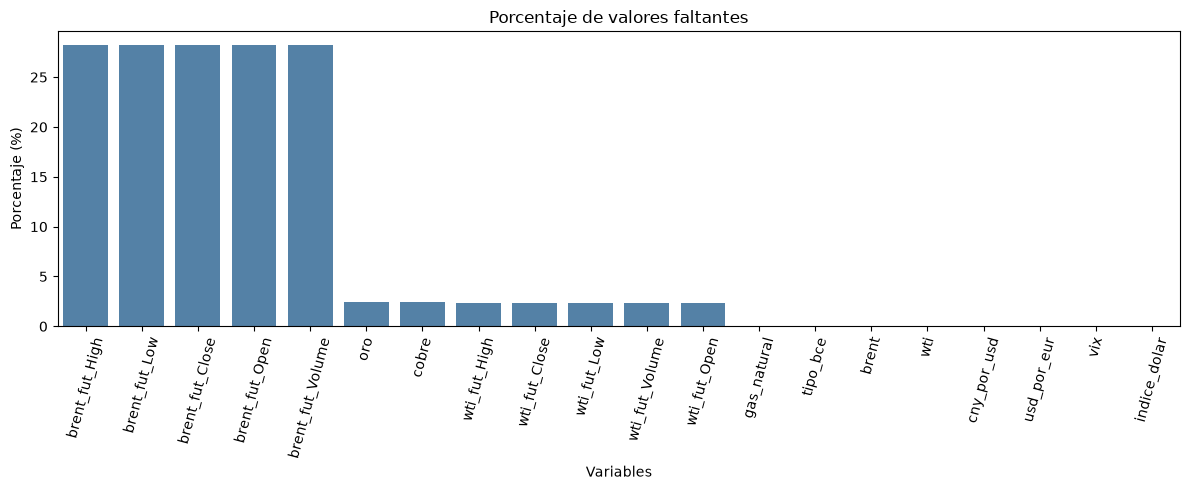

In [12]:
nulos = analizar_nulos(datos)

display(nulos)

graficar_nulos(datos)

### 4. ¿DESDE CUANDO HAY DATOS?

In [13]:
disponibilidad = disponibilidad_variables(datos)

display(disponibilidad)

,Primer dato,Último dato,Nulos,Porcentaje nulos
brent,2000-01-04,2026-11-05,0,0.00
wti,2000-01-04,2026-11-05,0,0.00
gas_natural,2000-01-10,2026-11-05,4,0.06
tipo_bce,2000-01-04,2026-11-05,0,0.00
usd_por_eur,2000-01-04,2026-11-05,0,0.00
cny_por_usd,2000-01-04,2026-11-05,0,0.00
vix,2000-01-04,2026-11-05,0,0.00
brent_fut_Open,2007-07-30,2026-11-05,1974,28.19
brent_fut_High,2007-07-30,2026-11-05,1974,28.19
brent_fut_Low,2007-07-30,2026-11-05,1974,28.19


### 5. EVOLUCIÓN HISTÓRICA DEL BRENT

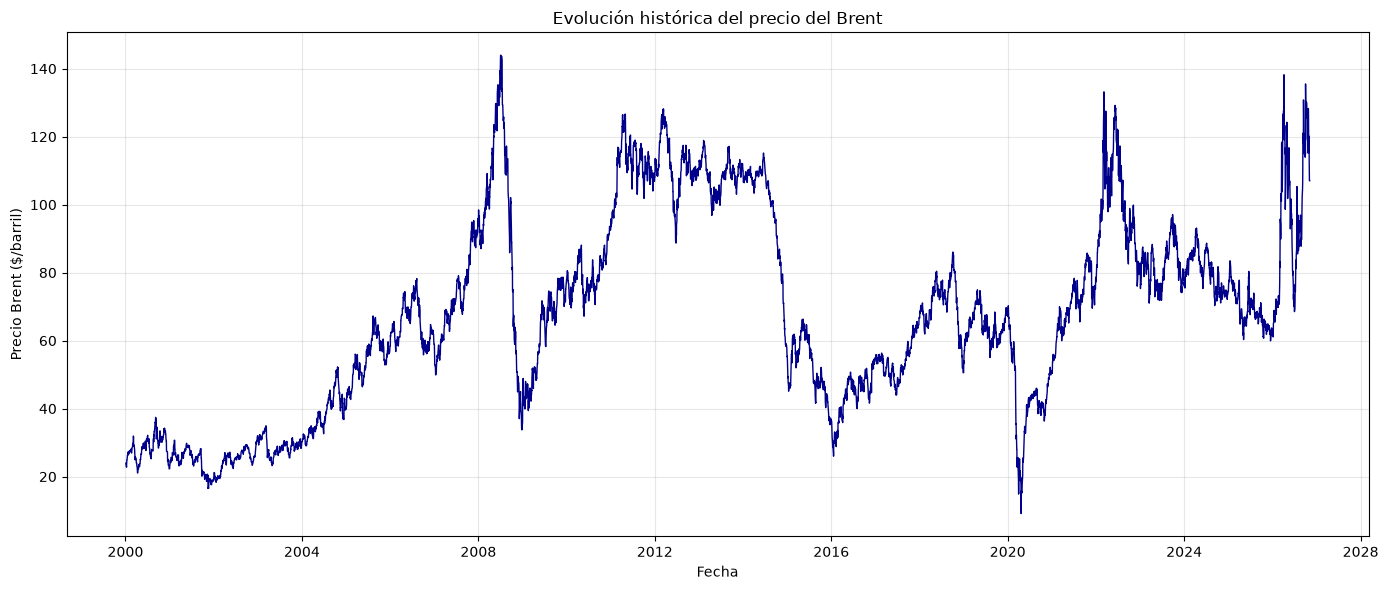

In [14]:
graficar_brent(datos)

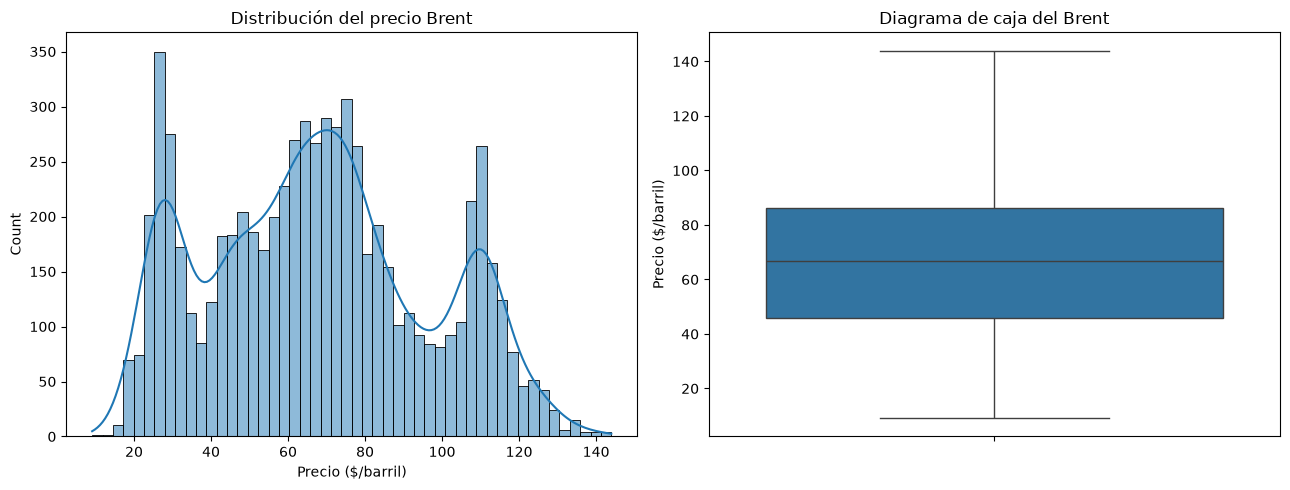

In [15]:
distribucion_brent(datos)

In [16]:
mayores, menores = valores_extremos(datos)

print("PRECIOS MÁS ALTOS:")
display(mayores)

print("PRECIOS MÁS BAJOS:")
display(menores)

PRECIOS MÁS ALTOS:


Date
2008-07-03    143.95
2008-07-04    143.95
2008-07-11    143.68
2008-07-14    142.43
2008-07-02    141.24
2008-07-01    140.67
2008-07-07    139.62
2008-06-27    139.38
2008-06-30    138.40
2026-04-07    138.21
Name: brent, dtype: float64

PRECIOS MÁS BAJOS:


Date
2020-04-21     9.12
2020-04-22    13.77
2020-03-31    14.85
2020-04-01    14.97
2020-04-23    15.06
2020-04-27    15.17
2020-04-28    15.60
2020-04-24    15.87
2001-11-15    16.51
2001-11-19    16.55
Name: brent, dtype: float64

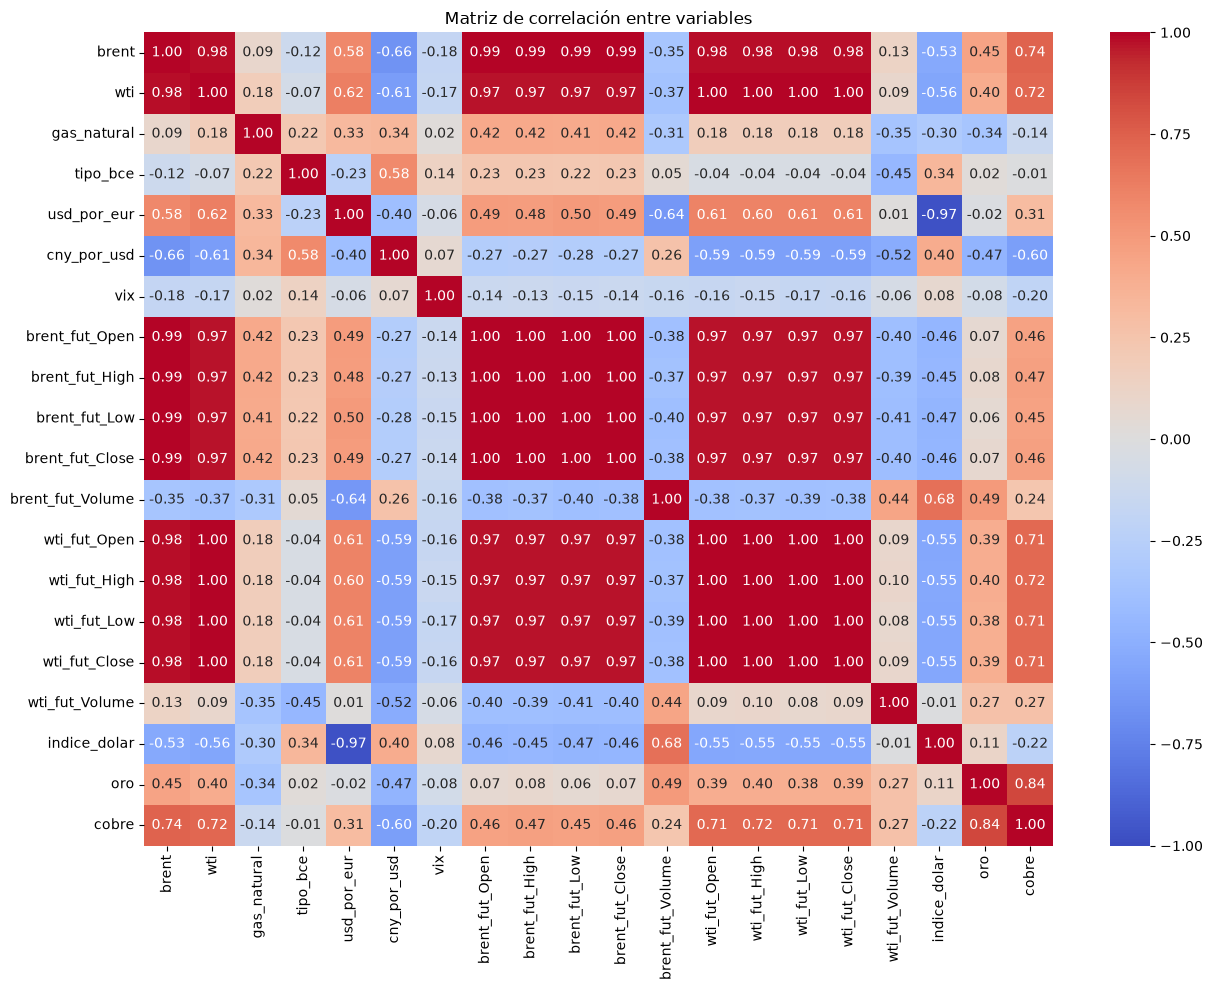

brent               1.000000
brent_fut_Close     0.994903
brent_fut_High      0.994745
brent_fut_Low       0.993434
brent_fut_Open      0.993432
wti                 0.982127
wti_fut_Close       0.980956
wti_fut_High        0.980732
wti_fut_Low         0.980672
wti_fut_Open        0.980493
cobre               0.739192
usd_por_eur         0.581687
oro                 0.449048
wti_fut_Volume      0.127309
gas_natural         0.091571
tipo_bce           -0.123996
vix                -0.176705
brent_fut_Volume   -0.349284
indice_dolar       -0.534728
cny_por_usd        -0.660345
Name: brent, dtype: float64

In [17]:
correlaciones = matriz_correlacion(datos)

display(
    correlaciones["brent"].sort_values(ascending=False)
)

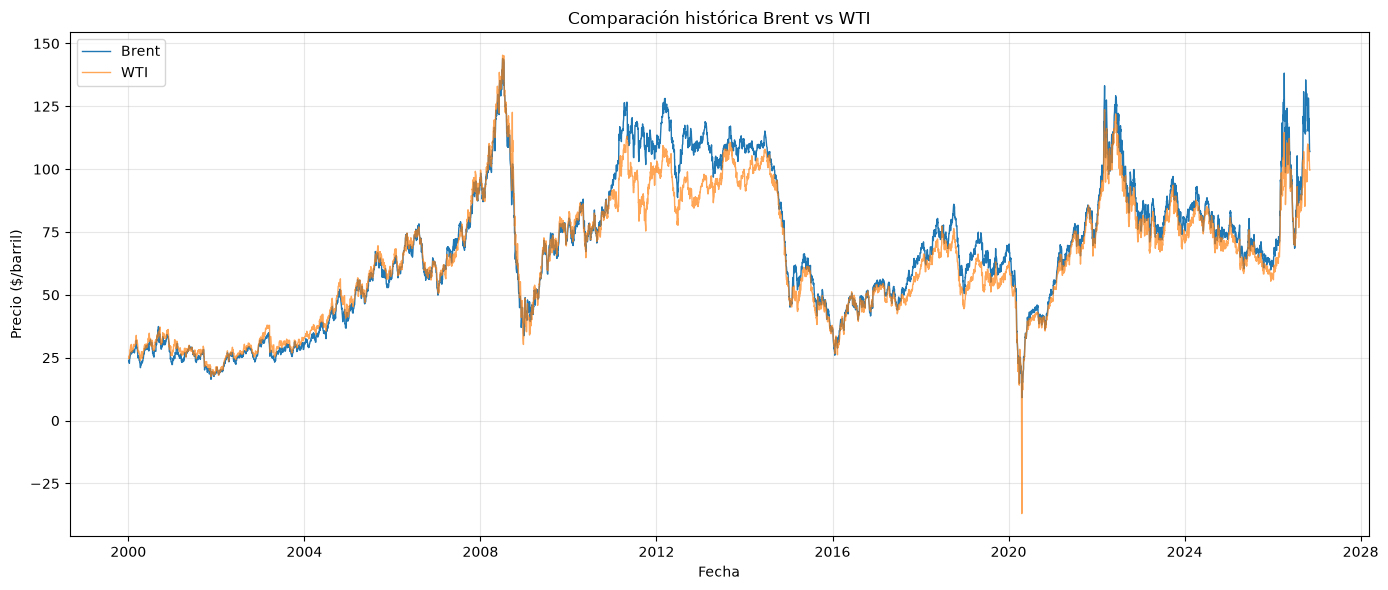

In [18]:
comparar_brent_wti(datos)

VALIDACIÓN DIARIA DEL BRENT: 

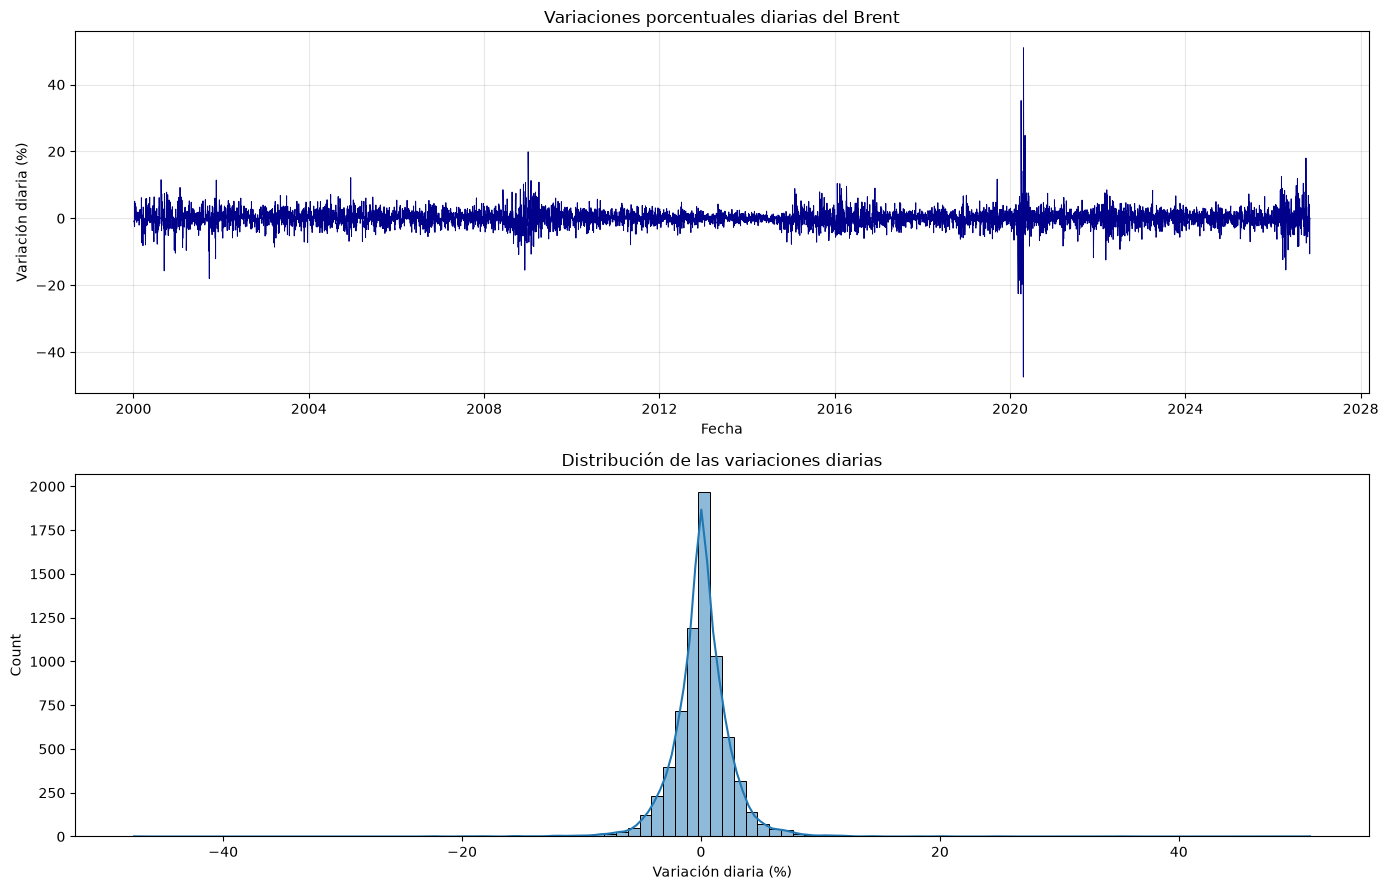

ESTADÍSTICAS DE LAS VARIACIONES:
count    7002.000000
mean        0.055868
std         2.613053
min       -47.465438
25%        -1.047997
50%         0.000000
75%         1.179599
max        50.986842
Name: brent, dtype: float64


In [19]:
from src.exploracion import analizar_variaciones_brent

variaciones = analizar_variaciones_brent(datos)

## MODELO 11 VARIABLES

## PREPROCESADO

Comprobar variables seleccionadas:

In [20]:
datos_modelo = preparar_variables(datos)

print("Dimensiones originales:", datos.shape)
print("Dimensiones después del preprocesamiento:", datos_modelo.shape)

print("\nVariables utilizadas:")
print(datos_modelo.columns.tolist())

display(datos_modelo.head())

Dimensiones originales: (7003, 20)
Dimensiones después del preprocesamiento: (6983, 11)

Variables utilizadas:
['brent', 'wti', 'gas_natural', 'tipo_bce', 'usd_por_eur', 'cny_por_usd', 'vix', 'indice_dolar', 'brent_ret', 'wti_ret', 'brent_vol_20']


,brent,wti,gas_natural,tipo_bce,usd_por_eur,cny_por_usd,vix,indice_dolar,brent_ret,wti_ret,brent_vol_20
Date,,,,,,,,,,,
2000-02-01,27.35,28.28,2.76,2.00,0.9731,8.2774,23.45,104.919998,0.997046,2.278481,1.983664
2000-02-02,27.15,27.52,2.76,2.00,0.9768,8.2773,23.12,104.790001,-0.731261,-2.687412,1.974308
2000-02-03,27.60,28.26,2.76,2.00,0.9887,8.2781,22.01,103.800003,1.657459,2.688953,1.956202
2000-02-04,27.48,28.67,2.76,2.25,0.9760,8.2788,21.54,104.290001,-0.434783,1.450814,1.939775
2000-02-07,27.48,28.67,2.76,2.25,0.9783,8.2788,22.79,104.639999,0.000000,0.000000,1.789797


Preparación de conjutos:

In [21]:
preprocesado = preparar_datasets(
    datos,
    ventana=60,
    horizontes=[5, 63, 252]
)

resultados = preprocesado["resultados"]

print("Variables de entrada:")
print(preprocesado["variables"])

Variables de entrada:
['brent', 'wti', 'gas_natural', 'tipo_bce', 'usd_por_eur', 'cny_por_usd', 'vix', 'indice_dolar', 'brent_ret', 'wti_ret', 'brent_vol_20']


Comprobar dimensiones:

In [22]:
for horizonte, conjuntos in resultados.items():

    print(f"\nHORIZONTE: {horizonte} DÍAS")

    print("Entrenamiento:")
    print("X:", conjuntos["X_train"].shape)
    print("y:", conjuntos["y_train"].shape)

    print("Validación:")
    print("X:", conjuntos["X_val"].shape)
    print("y:", conjuntos["y_val"].shape)

    print("Test:")
    print("X:", conjuntos["X_test"].shape)
    print("y:", conjuntos["y_test"].shape)


HORIZONTE: 5 DÍAS
Entrenamiento:
X: (4824, 60, 11)
y: (4824,)
Validación:
X: (1047, 60, 11)
y: (1047,)
Test:
X: (1048, 60, 11)
y: (1048,)

HORIZONTE: 63 DÍAS
Entrenamiento:
X: (4766, 60, 11)
y: (4766,)
Validación:
X: (1047, 60, 11)
y: (1047,)
Test:
X: (1048, 60, 11)
y: (1048,)

HORIZONTE: 252 DÍAS
Entrenamiento:
X: (4577, 60, 11)
y: (4577,)
Validación:
X: (1047, 60, 11)
y: (1047,)
Test:
X: (1048, 60, 11)
y: (1048,)


Comprobación fechas:

In [23]:
for horizonte, conjuntos in resultados.items():

    print(f"\nHORIZONTE: {horizonte} DÍAS")

    for nombre in ["train", "val", "test"]:

        fechas = conjuntos[f"fechas_{nombre}"]

        print(
            nombre,
            "Desde:", fechas.min(),
            "Hasta:", fechas.max()
        )


HORIZONTE: 5 DÍAS
train Desde: 2000-05-01 00:00:00 Hasta: 2018-10-25 00:00:00
val Desde: 2018-10-26 00:00:00 Hasta: 2022-10-31 00:00:00
test Desde: 2022-11-01 00:00:00 Hasta: 2026-11-05 00:00:00

HORIZONTE: 63 DÍAS
train Desde: 2000-07-20 00:00:00 Hasta: 2018-10-25 00:00:00
val Desde: 2018-10-26 00:00:00 Hasta: 2022-10-31 00:00:00
test Desde: 2022-11-01 00:00:00 Hasta: 2026-11-05 00:00:00

HORIZONTE: 252 DÍAS
train Desde: 2001-04-11 00:00:00 Hasta: 2018-10-25 00:00:00
val Desde: 2018-10-26 00:00:00 Hasta: 2022-10-31 00:00:00
test Desde: 2022-11-01 00:00:00 Hasta: 2026-11-05 00:00:00


In [24]:
for horizonte, conjuntos in resultados.items():

    print(f"\n{'='*40}")
    print(f"HORIZONTE: {horizonte} DÍAS")
    print(f"{'='*40}")

    for nombre in ["train", "val", "test"]:

        X = conjuntos[f"X_{nombre}"]
        y = conjuntos[f"y_{nombre}"]
        fechas = conjuntos[f"fechas_{nombre}"]

        print(f"\n{nombre.upper()}")
        print("X:", X.shape)
        print("y:", y.shape)
        print("Primera fecha:", fechas.min())
        print("Última fecha:", fechas.max())

        print("¿Hay NaN en X?:", np.isnan(X).any())
        print("¿Hay NaN en y?:", np.isnan(y).any())


HORIZONTE: 5 DÍAS

TRAIN
X: (4824, 60, 11)
y: (4824,)
Primera fecha: 2000-05-01 00:00:00
Última fecha: 2018-10-25 00:00:00
¿Hay NaN en X?: False
¿Hay NaN en y?: False

VAL
X: (1047, 60, 11)
y: (1047,)
Primera fecha: 2018-10-26 00:00:00
Última fecha: 2022-10-31 00:00:00
¿Hay NaN en X?: False
¿Hay NaN en y?: False

TEST
X: (1048, 60, 11)
y: (1048,)
Primera fecha: 2022-11-01 00:00:00
Última fecha: 2026-11-05 00:00:00
¿Hay NaN en X?: False
¿Hay NaN en y?: False

HORIZONTE: 63 DÍAS

TRAIN
X: (4766, 60, 11)
y: (4766,)
Primera fecha: 2000-07-20 00:00:00
Última fecha: 2018-10-25 00:00:00
¿Hay NaN en X?: False
¿Hay NaN en y?: False

VAL
X: (1047, 60, 11)
y: (1047,)
Primera fecha: 2018-10-26 00:00:00
Última fecha: 2022-10-31 00:00:00
¿Hay NaN en X?: False
¿Hay NaN en y?: False

TEST
X: (1048, 60, 11)
y: (1048,)
Primera fecha: 2022-11-01 00:00:00
Última fecha: 2026-11-05 00:00:00
¿Hay NaN en X?: False
¿Hay NaN en y?: False

HORIZONTE: 252 DÍAS

TRAIN
X: (4577, 60, 11)
y: (4577,)
Primera fecha: 2